In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image, ImageOps, UnidentifiedImageError
from skimage import measure, transform

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    recall_score,
    precision_score,
)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV

from sklearn.ensemble import RandomForestClassifier

### Data loading

In [2]:
DATA_DIR = Path("./data/Task 1 - Simple")

CLASSES = {
    "Potato___healthy": 0,
    "Potato___Early_blight": 1,
}

CLASS_NAMES = {0: "healthy", 1: "ill"}

In [3]:
def load_dataset(base_dir, classes):
    """Load all JPG images from class subfolders.

    Returns:
        images: list of PIL.Image objects in RGB mode
        labels: np.ndarray with one numeric label per image
        paths: list of source file paths
    """
    images, labels, paths = [], [], []

    for folder_name, label in classes.items():
        class_dir = base_dir / folder_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Missing folder: {class_dir}")

        for path in sorted(class_dir.iterdir()):
            try:
                with Image.open(path) as im:
                    # im = ImageOps.exif_transpose(im) # apply camera rotation from EXIF
                    img = im.convert("RGB")
            except (UnidentifiedImageError, OSError):
                print(f"Skipping unreadable file: {path}")
                continue

            images.append(img)
            labels.append(label)

    return images, np.array(labels)

In [4]:
images, labels = load_dataset(DATA_DIR, CLASSES)

for label, name in CLASS_NAMES.items():
    print(f"{name} (label {label}): {int(np.sum(labels == label))}")

healthy (label 0): 152
ill (label 1): 153


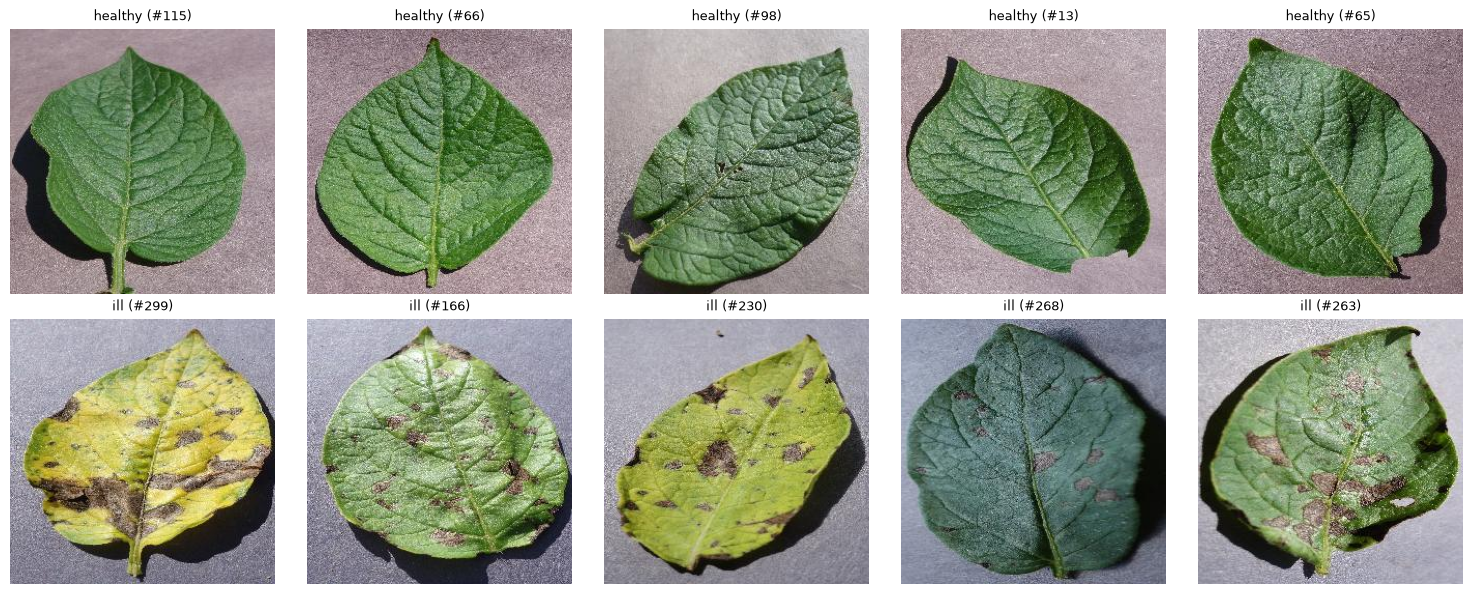

In [ ]:
def show_samples(images, labels, class_names, n_per_class=5, seed=42):
    """Show n random images per class, one row per class."""
    rng = np.random.default_rng(seed)
    classes = sorted(class_names)

    fig, axes = plt.subplots(
        len(classes), n_per_class, figsize=(3 * n_per_class, 3 * len(classes)), squeeze=False
    )

    for row, label in enumerate(classes):
        class_idx = np.flatnonzero(labels == label)
        chosen = rng.choice(class_idx, size=min(n_per_class, len(class_idx)), replace=False)

        for col in range(n_per_class):
            ax = axes[row, col]
            ax.axis("off")
            if col < len(chosen):
                ax.imshow(images[chosen[col]])
                ax.set_title(f"{class_names[label]} (#{chosen[col]})", fontsize=9)

    plt.tight_layout()
    plt.show()


show_samples(images, labels, CLASS_NAMES, n_per_class=5)

### Data splitting

In [5]:
idx = np.arange(len(images))
idx_train, idx_test = train_test_split(
    idx, test_size=0.3, stratify=labels, random_state=42
)

X_train = [images[i] for i in idx_train]
X_test = [images[i] for i in idx_test]
y_train = labels[idx_train]
y_test = labels[idx_test]

print(f"Train: {len(X_train)}, Test: {len(X_test)}")

Train: 213, Test: 92
